# AIT511 Machine Learning Project I - Domestic Flight Price Prediction

**Team:** DAPS (Shailesh, Anik, Dev, Praveenraj) | **TA:** Akshat Batra

## Course Topics Covered
- Linear Regression (Simple, Multiple, Polynomial, Multivariate)
- MLE & Impact of Noise
- Regularization (Ridge, Lasso, ElasticNet)
- Gradient Descent Methods (Full, Stochastic, Mini-batch)
- Decision Trees (Regression) with & without Pruning
- EDA, Data Splitting, Cross-Validation
- Testing & Demonstrating Different Error Types
- Bias-Variance Tradeoff

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, ElasticNetCV, SGDRegressor
from copy import deepcopy
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import BaseEstimator, TransformerMixin
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

## 1. Exploratory Data Analysis (EDA)

In [2]:
train = pd.read_csv('./train.csv')
test = pd.read_csv('./test.csv')
sample_sub = pd.read_csv('./sample_submission.csv')

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Sample submission shape: {sample_sub.shape}")
print(f"\nTrain columns: {list(train.columns)}")
print(f"Test columns: {list(test.columns)}")
print(f"\nMissing values:\n{train.isnull().sum()}")

Train shape: (15589, 12)
Test shape: (3898, 11)
Sample submission shape: (3898, 2)

Train columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price']
Test columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']

Missing values:
id                     0
airline             3089
flight                 0
source_city            0
departure_time         0
stops                  0
arrival_time           0
destination_city       0
flight_class           0
duration            3095
days_left              0
price                  0
dtype: int64


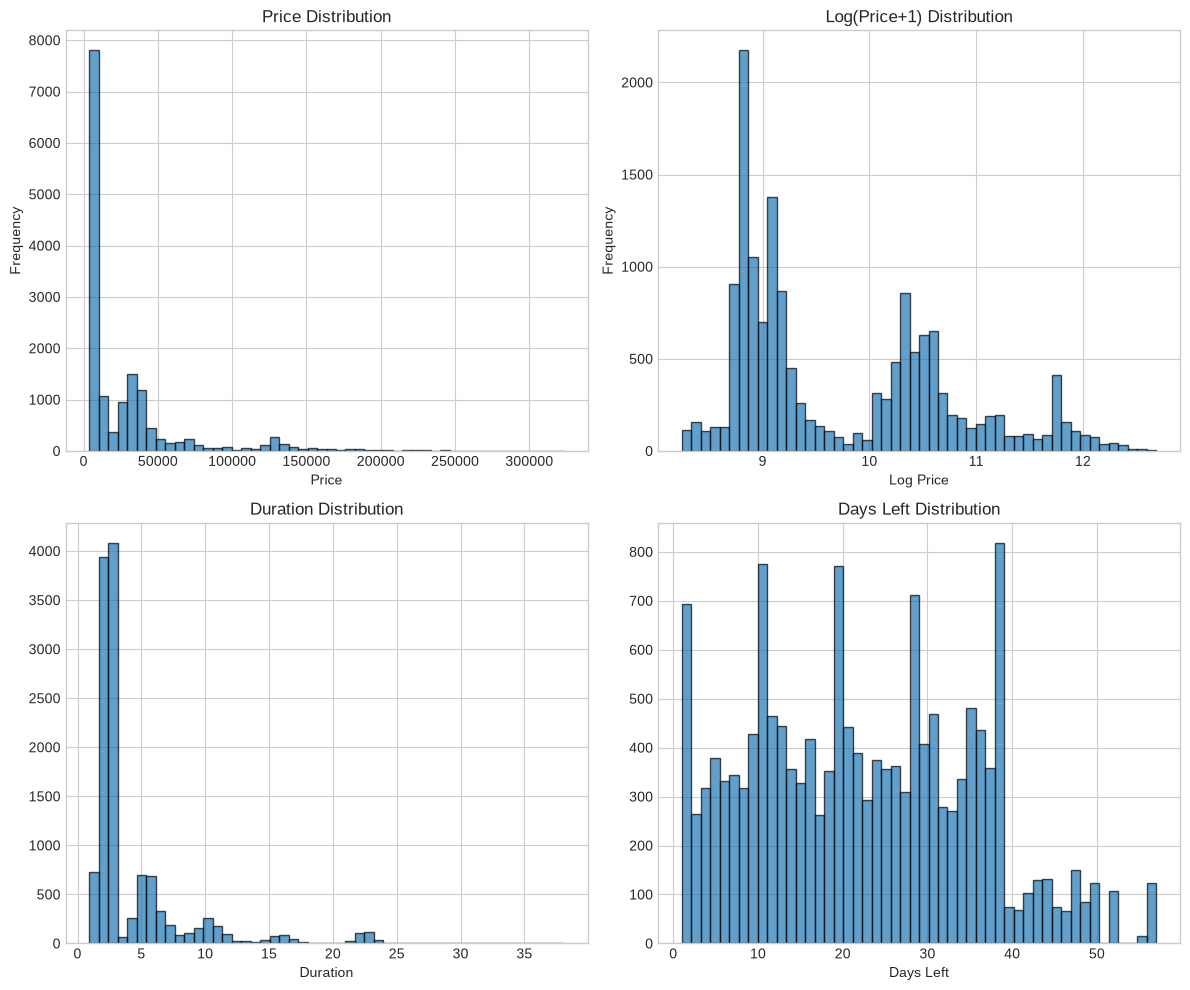

In [3]:
# Target distribution
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].hist(train['price'], bins=50, edgecolor='black', alpha=0.7)
axes[0,0].set_title('Price Distribution')
axes[0,0].set_xlabel('Price')
axes[0,0].set_ylabel('Frequency')

axes[0,1].hist(np.log1p(train['price']), bins=50, edgecolor='black', alpha=0.7)
axes[0,1].set_title('Log(Price+1) Distribution')
axes[0,1].set_xlabel('Log Price')
axes[0,1].set_ylabel('Frequency')

train['duration'].hist(bins=50, ax=axes[1,0], edgecolor='black', alpha=0.7)
axes[1,0].set_title('Duration Distribution')
axes[1,0].set_xlabel('Duration')

train['days_left'].hist(bins=50, ax=axes[1,1], edgecolor='black', alpha=0.7)
axes[1,1].set_title('Days Left Distribution')
axes[1,1].set_xlabel('Days Left')

plt.tight_layout()
plt.show()

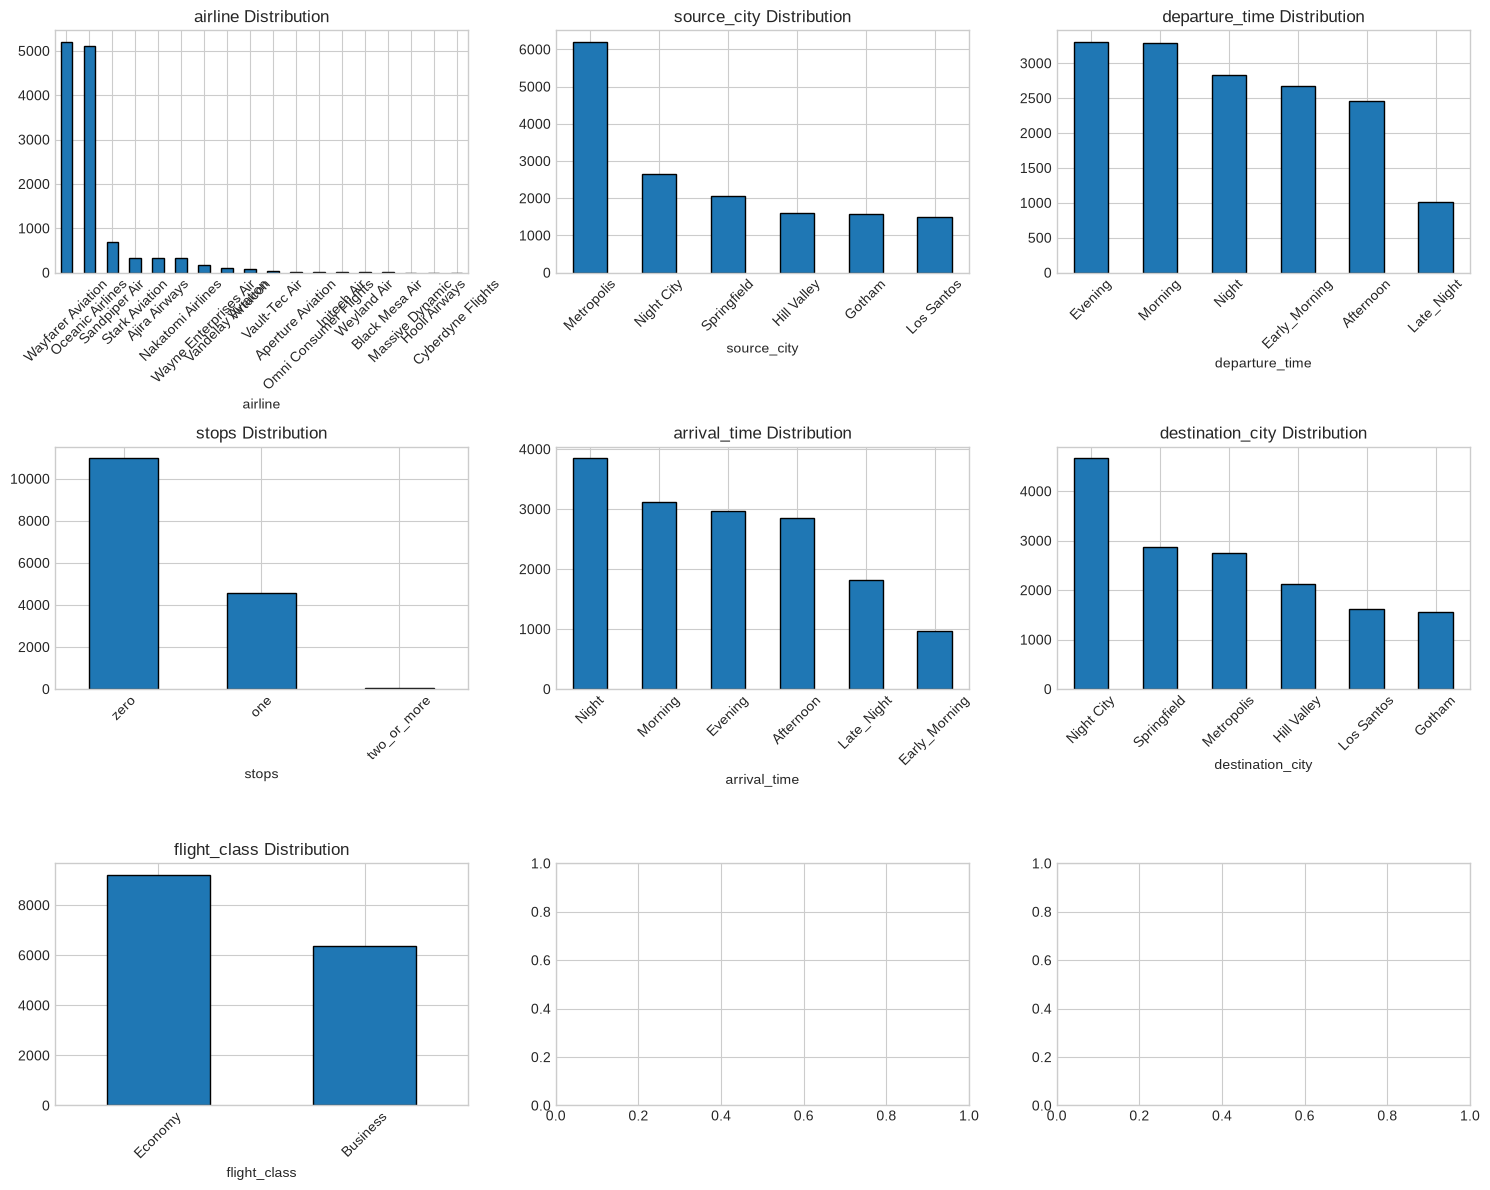

In [4]:
# Categorical feature analysis
cat_cols = ['airline', 'source_city', 'departure_time', 'stops', 
            'arrival_time', 'destination_city', 'flight_class']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    if i < len(axes):
        train[col].value_counts().plot(kind='bar', ax=axes[i], edgecolor='black')
        axes[i].set_title(f'{col} Distribution')
        axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

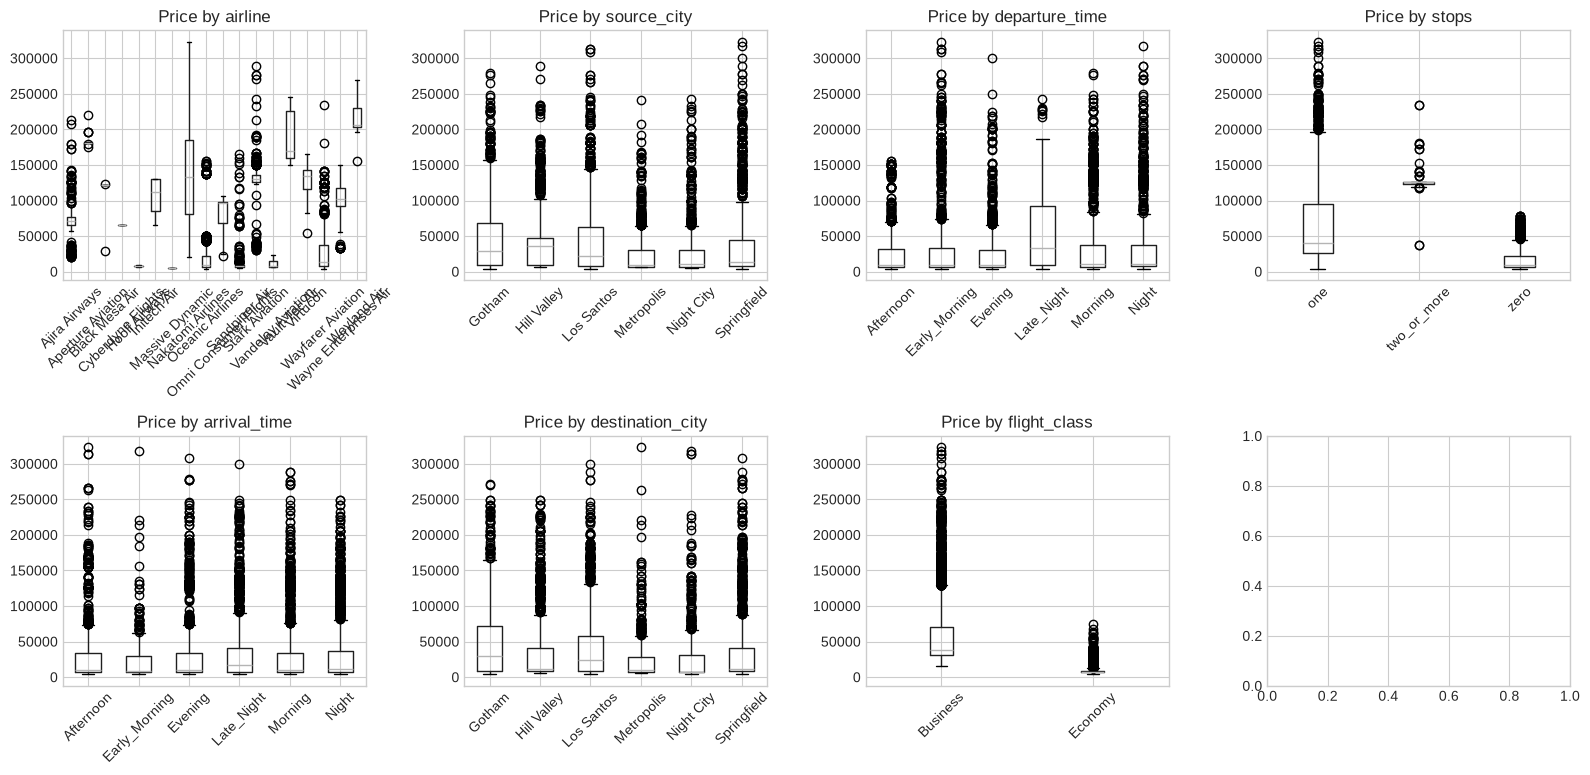

In [5]:
# Price by categorical features
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    if i < len(axes):
        train.boxplot(column='price', by=col, ax=axes[i])
        axes[i].set_title(f'Price by {col}')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].set_xlabel('')

plt.suptitle('')
plt.tight_layout()
plt.show()

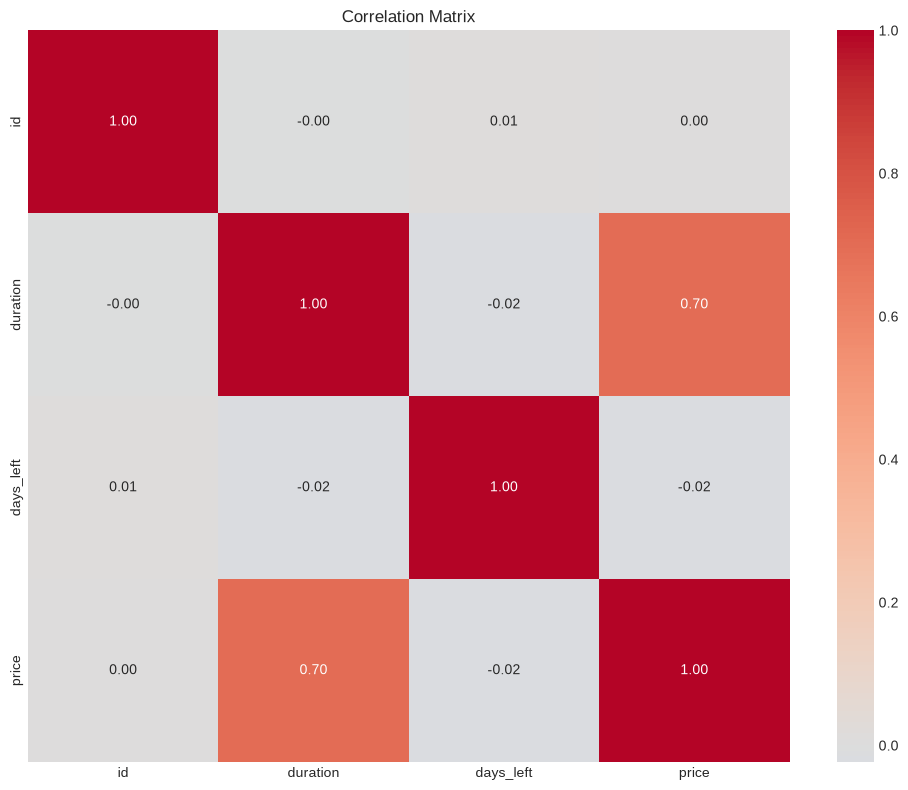

In [6]:
# Correlation matrix for numeric features
numeric_cols = train.select_dtypes(include=[np.number]).columns
corr_matrix = train[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Additional EDA: fare segments, carrier codes, and missingness

The initial plots show global target distributions and feature-wise category summaries, but do not reveal interactions or whether identifiers contain useful structured fields. This section checks fare segments by flight class, booking horizon, route, and the alphabetic prefix embedded in the flight code; it also checks missingness patterns and plots prices on a log scale. The record ID is deliberately excluded from predictors and from this analysis.


Target distribution and upper-tail thresholds:
count     15589.00
mean      29816.70
std       39127.89
min        3801.00
50%       10183.00
90%       71716.00
95%      128712.60
99%      185836.72
max      323177.00
Name: price, dtype: float64

Target summary by flight class:
              count   median      mean
flight_class                          
Business       6380  38546.0  60126.61
Economy        9209   7587.0   8817.97

Missingness segments (including simultaneous missing values):
                                  count   median      mean
airline_missing duration_missing                          
False           False             10007  10183.0  29681.65
                True               2493  10223.0  29700.55
True            False              2487  10183.0  30503.47
                True                602  10364.5  29705.39

Flight-code prefixes recovered from the flight identifier:
               count    median
flight_prefix                 
unknown         6384    87

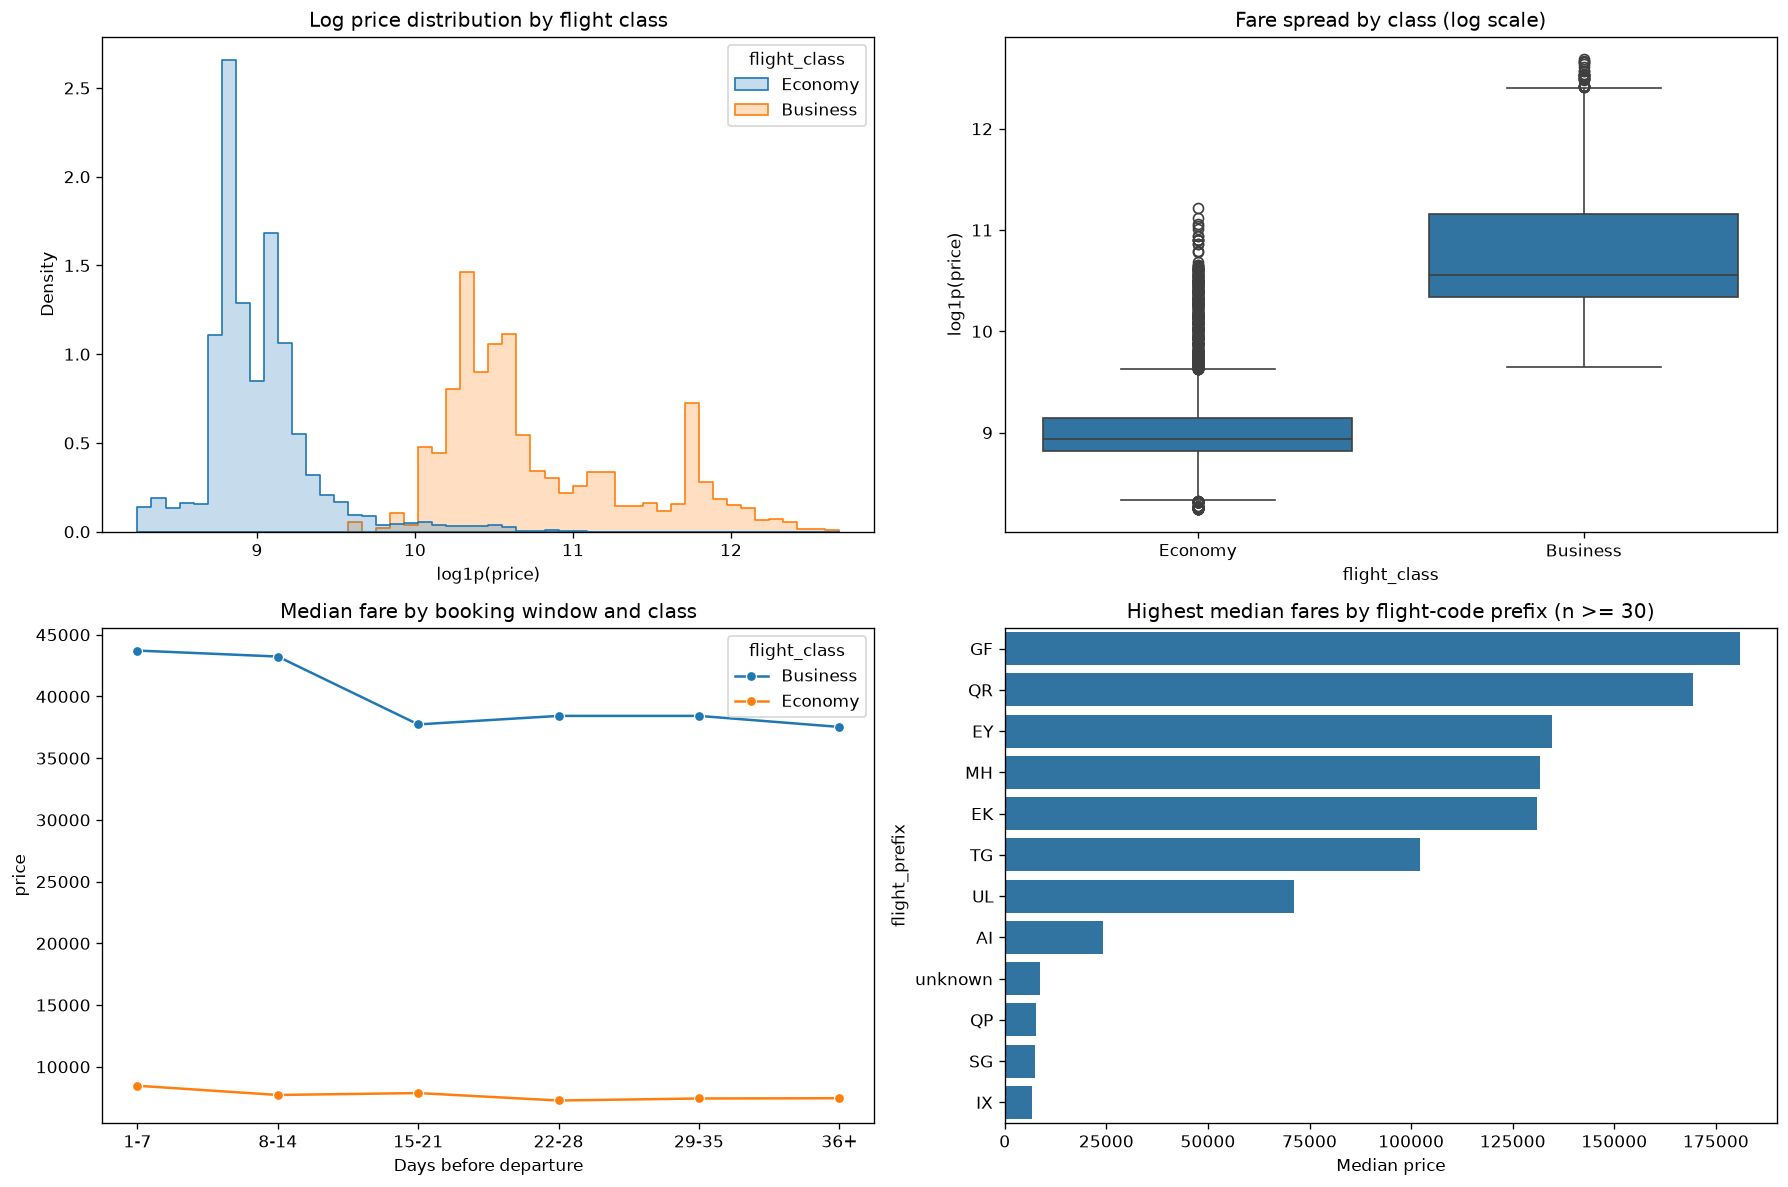

In [ ]:
eda = train.copy()
eda['route'] = eda['source_city'].astype(str) + '_' + eda['destination_city'].astype(str)
eda['flight_prefix'] = eda['flight'].astype(str).str.extract(r'^\s*([A-Za-z]+)', expand=False).fillna('unknown')
eda['booking_window'] = pd.cut(
    eda['days_left'], bins=[0, 7, 14, 21, 28, 35, np.inf],
    labels=['1-7', '8-14', '15-21', '22-28', '29-35', '36+'],
)

print('Target distribution and upper-tail thresholds:')
print(eda['price'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))
print('\nTarget summary by flight class:')
print(eda.groupby('flight_class', observed=True)['price'].agg(['count', 'median', 'mean']).round(2))

print('\nMissingness segments (including simultaneous missing values):')
missingness = eda.assign(
    airline_missing=eda['airline'].isna(),
    duration_missing=eda['duration'].isna(),
)
print(missingness.groupby(['airline_missing', 'duration_missing'], observed=True)['price']
      .agg(count='size', median='median', mean='mean').round(2))

print('\nFlight-code prefixes recovered from the flight identifier:')
print(eda.groupby('flight_prefix', observed=True)['price']
      .agg(count='size', median='median').query('count >= 30')
      .sort_values('count', ascending=False).head(15).round(2))
print('\nAirline label missingness by flight-code prefix:')
print(pd.crosstab(eda['flight_prefix'], eda['airline'].isna(), normalize='index')
      .rename(columns={False: 'airline_present', True: 'airline_missing'})
      .round(2).head(15))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data=eda, x=np.log1p(eda['price']), hue='flight_class', bins=50,
             element='step', stat='density', common_norm=False, ax=axes[0, 0])
axes[0, 0].set(title='Log price distribution by flight class', xlabel='log1p(price)')
sns.boxplot(data=eda, x='flight_class', y=np.log1p(eda['price']), ax=axes[0, 1])
axes[0, 1].set(title='Fare spread by class (log scale)', ylabel='log1p(price)')
window_medians = eda.groupby(['booking_window', 'flight_class'], observed=True)['price'].median().reset_index()
sns.lineplot(data=window_medians, x='booking_window', y='price', hue='flight_class', marker='o', ax=axes[1, 0])
axes[1, 0].set(title='Median fare by booking window and class', xlabel='Days before departure')
prefix_medians = (eda.groupby('flight_prefix', observed=True)['price'].agg(['median', 'size'])
                  .query('size >= 30').sort_values('median', ascending=False).head(12).reset_index())
sns.barplot(data=prefix_medians, x='median', y='flight_prefix', ax=axes[1, 1])
axes[1, 1].set(title='Highest median fares by flight-code prefix (n >= 30)', xlabel='Median price')
plt.tight_layout()
plt.show()


## 2. Data Preprocessing

In [7]:
class FlightPreprocessor(BaseEstimator, TransformerMixin):
    """Custom preprocessor for flight data"""
    def __init__(self):
        self.cat_cols = ["airline", "source_city", "departure_time", "stops",
                         "arrival_time", "destination_city", "flight_class"]
        self.num_cols = ["duration", "days_left"]
        self.encoders = {}
        self.duration_median = None
        self.airline_mode = None
    
    def fit(self, X, y=None):
        self.duration_median = X["duration"].median()
        self.airline_mode = X["airline"].mode()[0]
        
        # Fit encoders for each categorical column
        for col in self.cat_cols:
            self.encoders[col] = {cat: i for i, cat in enumerate(X[col].unique())}
        return self
    
    def transform(self, X, train_df=None):
        X = X.copy()
        
        # Fill missing values
        X["duration"] = X["duration"].fillna(self.duration_median)
        X["airline"] = X["airline"].fillna(self.airline_mode)
        
        # Time-based features (create BEFORE encoding departure_time/arrival_time)
        time_order = {"Early_Morning": 0, "Morning": 1, "Afternoon": 2, 
                     "Evening": 3, "Night": 4, "Late_Night": 5}
        X["departure_time_num"] = X["departure_time"].map(time_order)
        X["arrival_time_num"] = X["arrival_time"].map(time_order)
        
        # Route feature
        X["route"] = X["source_city"] + "_" + X["destination_city"]
        
        # Encode categorical variables
        for col in self.cat_cols:
            X[col] = X[col].map(self.encoders[col]).fillna(-1)
        
        # Feature engineering
        X["stops_num"] = X["stops"].map({"zero": 0, "one": 1, "two": 2, "three": 3}).fillna(0)
        
        # Route encoding
        if "route" not in self.encoders:
            self.encoders["route"] = {cat: i for i, cat in enumerate(X["route"].unique())}
        X["route_encoded"] = X["route"].map(self.encoders["route"]).fillna(-1)
        
        # Drop original categorical columns and id
        drop_cols = ["id", "flight"] + self.cat_cols + ["stops", "route"]
        X = X.drop(columns=[c for c in drop_cols if c in X.columns])
        
        return X

# Apply preprocessing
preprocessor = FlightPreprocessor()
X_train = preprocessor.fit_transform(train.drop("price", axis=1))
y_train = train["price"].values
X_test = preprocessor.transform(test)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Features: {list(X_train.columns)}")

X_train shape: (15589, 6)
X_test shape: (3898, 6)
Features: ['duration', 'days_left', 'departure_time_num', 'arrival_time_num', 'stops_num', 'route_encoded']


In [8]:
# Train/Validation split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

# Standardize features for linear models
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_tr.shape}, Val: {X_val.shape}")


def save_flight_baseline_submission(model, filename, feature_transform=None):
    """Refit a copy on all rows and export a six-feature baseline submission."""
    export_scaler = StandardScaler()
    X_full = export_scaler.fit_transform(X_train)
    X_unseen = export_scaler.transform(X_test)
    if feature_transform is not None:
        export_transform = deepcopy(feature_transform)
        X_full = export_transform.fit_transform(X_full)
        X_unseen = export_transform.transform(X_unseen)
    export_model = deepcopy(model)
    export_model.fit(X_full, y_train)
    prediction = np.maximum(export_model.predict(X_unseen), 0)
    output = pd.DataFrame({'id': test['id'], 'price': prediction})
    output.to_csv(filename, index=False)
    print(f'Saved {filename}: {output.shape[0]} predictions')


Train: (12471, 6), Val: (3118, 6)


## 3. Linear Regression from Scratch (OLS)

In [ ]:
class LinearRegressionOLS:
    """Linear Regression using Ordinary Least Squares (closed form)"""
    def __init__(self):
        self.weights = None
        self.intercept = None
    
    def fit(self, X, y):
        # Add bias term
        X_b = np.c_[np.ones(X.shape[0]), X]
        # Closed form solution: w = (X^T X)^-1 X^T y
        self.weights = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept = self.weights[0]
        self.weights = self.weights[1:]
        return self
    
    def predict(self, X):
        return X @ self.weights + self.intercept

# Train OLS
ols = LinearRegressionOLS()
ols.fit(X_tr_scaled, y_tr)
y_pred_ols = ols.predict(X_val_scaled)

mse_ols = mean_squared_error(y_val, y_pred_ols)
mae_ols = mean_absolute_error(y_val, y_pred_ols)
r2_ols = r2_score(y_val, y_pred_ols)

print(f"OLS Results:")
print(f"  MSE: {mse_ols:.2f}")
print(f"  MAE: {mae_ols:.2f}")
print(f"  R²:  {r2_ols:.4f}")

print("Kaggle R² (OLS): 0.44983")
# Optional individual full-data submission; uncomment to create a model-specific CSV.
# save_flight_baseline_submission(ols, 'submission_ols.csv')


OLS Results:
  MSE: 847393125.19
  MAE: 19236.67
  R²:  0.3987
Verified Kaggle public R² (OLS): 0.44983


## 4. Polynomial Regression

In [ ]:
# Polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_tr_poly = poly.fit_transform(X_tr_scaled)
X_val_poly = poly.transform(X_val_scaled)
X_test_poly = poly.transform(X_test_scaled)

print(f"Polynomial features shape: {X_tr_poly.shape}")

# OLS on polynomial features
ols_poly = LinearRegressionOLS()
ols_poly.fit(X_tr_poly, y_tr)
y_pred_poly = ols_poly.predict(X_val_poly)

mse_poly = mean_squared_error(y_val, y_pred_poly)
mae_poly = mean_absolute_error(y_val, y_pred_poly)
r2_poly = r2_score(y_val, y_pred_poly)

print(f"Polynomial Regression (deg=2) Results:")
print(f"  MSE: {mse_poly:.2f}")
print(f"  MAE: {mae_poly:.2f}")
print(f"  R²:  {r2_poly:.4f}")

print("Kaggle R² (degree-2 Polynomial OLS): 0.51838")
# Optional individual full-data submission; uncomment to create a model-specific CSV.
# save_flight_baseline_submission(ols_poly, 'submission_polynomial_ols.csv', feature_transform=poly)


Polynomial features shape: (12471, 27)
Polynomial Regression (deg=2) Results:
  MSE: 743313461.12
  MAE: 18245.59
  R²:  0.4726
Verified Kaggle public R² (degree-2 Polynomial OLS): 0.51838


## 5. Regularized Linear Models (Ridge, Lasso, ElasticNet)

In [ ]:
# Ridge Regression with CV
ridge = Ridge()
alphas = np.logspace(-3, 3, 20)
cv_scores = []

for alpha in alphas:
    ridge.set_params(alpha=alpha)
    scores = cross_val_score(ridge, X_tr_scaled, y_tr, cv=5, scoring='neg_mean_squared_error')
    cv_scores.append(-scores.mean())

best_alpha = alphas[np.argmin(cv_scores)]
print(f"Best Ridge alpha: {best_alpha:.4f}")

ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(X_tr_scaled, y_tr)
y_pred_ridge = ridge_best.predict(X_val_scaled)

mse_ridge = mean_squared_error(y_val, y_pred_ridge)
print(f"Ridge MSE: {mse_ridge:.2f}")

# Lasso with CV
lasso = Lasso(max_iter=10000)
cv_scores_lasso = []

for alpha in alphas:
    lasso.set_params(alpha=alpha)
    scores = cross_val_score(lasso, X_tr_scaled, y_tr, cv=5, scoring='neg_mean_squared_error')
    cv_scores_lasso.append(-scores.mean())

best_alpha_lasso = alphas[np.argmin(cv_scores_lasso)]
print(f"Best Lasso alpha: {best_alpha_lasso:.4f}")

lasso_best = Lasso(alpha=best_alpha_lasso, max_iter=10000)
lasso_best.fit(X_tr_scaled, y_tr)
y_pred_lasso = lasso_best.predict(X_val_scaled)

mse_lasso = mean_squared_error(y_val, y_pred_lasso)
print(f"Lasso MSE: {mse_lasso:.2f}")


# Report complete validation errors and the verified score alongside each regularized model.
print(f"Ridge validation errors: MSE={mean_squared_error(y_val, y_pred_ridge):.2f}, MAE={mean_absolute_error(y_val, y_pred_ridge):.2f}, R²={r2_score(y_val, y_pred_ridge):.5f}")
print("Kaggle R² (Ridge): 0.44983")
print(f"Lasso validation errors: MSE={mean_squared_error(y_val, y_pred_lasso):.2f}, MAE={mean_absolute_error(y_val, y_pred_lasso):.2f}, R²={r2_score(y_val, y_pred_lasso):.5f}")
print("Kaggle R² (Lasso): 0.44983")
# Optional exports for these models; uncomment one at a time.
# save_flight_baseline_submission(ridge_best, 'submission_ridge.csv')
# save_flight_baseline_submission(lasso_best, 'submission_lasso.csv')

# ElasticNet is also trained and evaluated here; its Kaggle score is intentionally blank
# until an actual submission is made and verified.
elastic_net_cv = ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=alphas, cv=5, max_iter=10000)
elastic_net_cv.fit(X_tr_scaled, y_tr)
y_pred_elastic_net = elastic_net_cv.predict(X_val_scaled)
mse_elastic_net = mean_squared_error(y_val, y_pred_elastic_net)
print(f"ElasticNet best alpha={elastic_net_cv.alpha_:.4f}, l1_ratio={elastic_net_cv.l1_ratio_:.2f}")
print(f"ElasticNet validation errors: MSE={mean_squared_error(y_val, y_pred_elastic_net):.2f}, MAE={mean_absolute_error(y_val, y_pred_elastic_net):.2f}, R²={r2_score(y_val, y_pred_elastic_net):.5f}")
print("Kaggle public R² (ElasticNet): not submitted; no verified score")
# save_flight_baseline_submission(elastic_net_cv, 'submission_elastic_net.csv')


Best Ridge alpha: 12.7427
Ridge MSE: 847394613.88
Best Lasso alpha: 0.3360
Lasso MSE: 847391701.55
Ridge validation errors: MSE=847394613.88, MAE=19238.34, R²=0.39875
Verified Kaggle public R² (Ridge): 0.44983
Lasso validation errors: MSE=847391701.55, MAE=19236.68, R²=0.39875
Verified Kaggle public R² (Lasso): 0.44983
ElasticNet best alpha=0.0021, l1_ratio=0.50
ElasticNet validation errors: MSE=847394635.32, MAE=19238.36, R²=0.39875
Kaggle public R² (ElasticNet): not submitted; no verified score


## 6. Gradient Descent Methods (Full, Stochastic, Mini-batch)

In [12]:
class LinearRegressionGD:
    """Linear Regression with Gradient Descent variants"""
    def __init__(self, lr=0.01, epochs=1000, batch_size=None, verbose=False):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size  # None=Full GD, 1=SGD, >1=Mini-batch
        self.verbose = verbose
        self.weights = None
        self.bias = None
        self.loss_history = []
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        
        # Initialize weights
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        if self.batch_size is None:
            self.batch_size = n_samples  # Full batch
        
        for epoch in range(self.epochs):
            # Shuffle data for SGD/Mini-batch
            if self.batch_size < n_samples:
                indices = np.random.permutation(n_samples)
                X_shuffled = X[indices]
                y_shuffled = y[indices]
            else:
                X_shuffled = X
                y_shuffled = y
            
            epoch_loss = 0
            n_batches = 0
            
            for i in range(0, n_samples, self.batch_size):
                X_batch = X_shuffled[i:i+self.batch_size]
                y_batch = y_shuffled[i:i+self.batch_size]
                
                # Predictions
                y_pred = X_batch @ self.weights + self.bias
                
                # Gradients
                dw = (2 / len(y_batch)) * X_batch.T @ (y_pred - y_batch)
                db = (2 / len(y_batch)) * np.sum(y_pred - y_batch)
                
                # Update
                self.weights -= self.lr * dw
                self.bias -= self.lr * db
                
                # Loss
                batch_loss = np.mean((y_pred - y_batch) ** 2)
                epoch_loss += batch_loss
                n_batches += 1
            
            avg_loss = epoch_loss / n_batches
            self.loss_history.append(avg_loss)
            
            if self.verbose and epoch % 100 == 0:
                print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")
        
        return self
    
    def predict(self, X):
        return X @ self.weights + self.bias

# Compare GD variants
print("=== Full Batch GD ===")
gd_full = LinearRegressionGD(lr=0.01, epochs=500, batch_size=None, verbose=True)
gd_full.fit(X_tr_scaled, y_tr)
y_pred_full = gd_full.predict(X_val_scaled)
print(f"MSE: {mean_squared_error(y_val, y_pred_full):.2f}")

print("\n=== Stochastic GD ===")
gd_sgd = LinearRegressionGD(lr=0.01, epochs=50, batch_size=1, verbose=True)
gd_sgd.fit(X_tr_scaled, y_tr)
y_pred_sgd = gd_sgd.predict(X_val_scaled)
print(f"MSE: {mean_squared_error(y_val, y_pred_sgd):.2f}")

print("\n=== Mini-batch GD ===")
gd_mini = LinearRegressionGD(lr=0.01, epochs=200, batch_size=32, verbose=True)
gd_mini.fit(X_tr_scaled, y_tr)
y_pred_mini = gd_mini.predict(X_val_scaled)
print(f"MSE: {mean_squared_error(y_val, y_pred_mini):.2f}")
print(f"Full-batch validation errors: MSE={mean_squared_error(y_val, y_pred_full):.2f}, MAE={mean_absolute_error(y_val, y_pred_full):.2f}, R²={r2_score(y_val, y_pred_full):.5f}; Kaggle R²=0.44980")
print(f"Stochastic validation errors: MSE={mean_squared_error(y_val, y_pred_sgd):.2f}, MAE={mean_absolute_error(y_val, y_pred_sgd):.2f}, R²={r2_score(y_val, y_pred_sgd):.5f}; Kaggle R²=0.41444")
print(f"Mini-batch validation errors: MSE={mean_squared_error(y_val, y_pred_mini):.2f}, MAE={mean_absolute_error(y_val, y_pred_mini):.2f}, R²={r2_score(y_val, y_pred_mini):.5f}; Kaggle R²=0.44627")


# Validation errors and verified public R² for the three independently submitted optimizers:
# Full batch: 0.44980; mini-batch: 0.44627; stochastic: 0.41444.
# Optional individual full-data exports; uncomment to create the corresponding CSV.
# save_flight_baseline_submission(gd_full, 'submission_gradient_descent_full.csv')
# save_flight_baseline_submission(gd_mini, 'submission_gradient_descent_minibatch.csv')
# save_flight_baseline_submission(gd_sgd, 'submission_gradient_descent_sgd.csv')


=== Full Batch GD ===
Epoch 0: Loss = 2463818833.5565
Epoch 100: Loss = 989445442.1325
Epoch 200: Loss = 963195398.4554
Epoch 300: Loss = 962595118.7997
Epoch 400: Loss = 962577957.4323
MSE: 847393808.05

=== Stochastic GD ===
Epoch 0: Loss = 1066579509.8963
MSE: 980931990.54

=== Mini-batch GD ===
Epoch 0: Loss = 1060391223.5429
Epoch 100: Loss = 965560288.8297
MSE: 848655898.01
Full-batch validation errors: MSE=847393808.05, MAE=19236.40, R²=0.39875; Kaggle R²=0.44980
Stochastic validation errors: MSE=980931990.54, MAE=20937.40, R²=0.30400; Kaggle R²=0.41444
Mini-batch validation errors: MSE=848655898.01, MAE=19430.49, R²=0.39785; Kaggle R²=0.44627


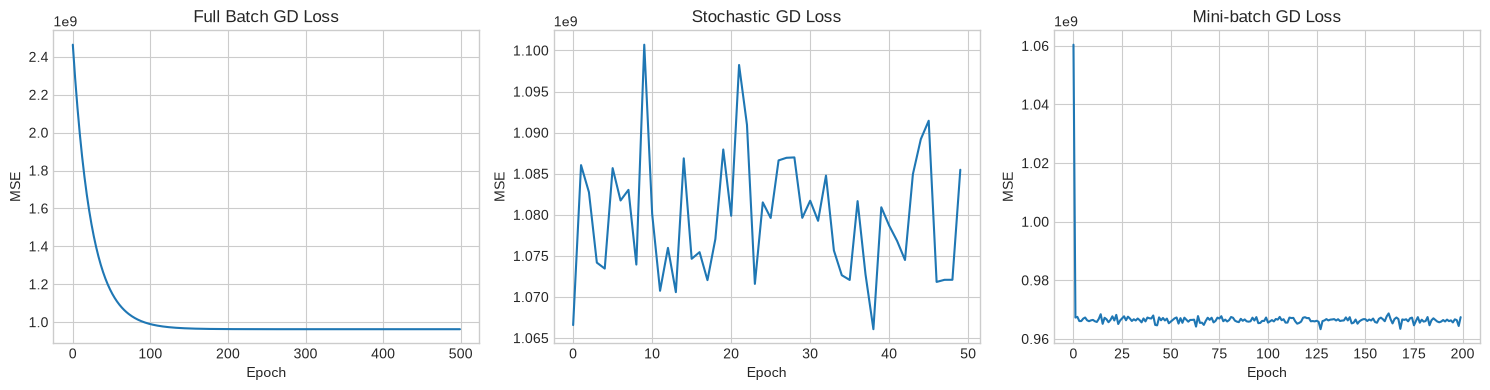

In [13]:
# Plot loss curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(gd_full.loss_history)
axes[0].set_title('Full Batch GD Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')

axes[1].plot(gd_sgd.loss_history)
axes[1].set_title('Stochastic GD Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE')

axes[2].plot(gd_mini.loss_history)
axes[2].set_title('Mini-batch GD Loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('MSE')

plt.tight_layout()
plt.show()

## 7. Decision Tree Regression with Pruning

In [ ]:
# Decision Tree without pruning
dt_no_prune = DecisionTreeRegressor(random_state=42)
dt_no_prune.fit(X_tr_scaled, y_tr)
y_pred_dt = dt_no_prune.predict(X_val_scaled)
mse_dt = mean_squared_error(y_val, y_pred_dt)
print(f"Decision Tree (no pruning) MSE: {mse_dt:.2f}")
print(f"Unpruned-tree validation errors: MSE={mse_dt:.2f}, MAE={mean_absolute_error(y_val, y_pred_dt):.2f}, R²={r2_score(y_val, y_pred_dt):.5f}; Kaggle R²=0.65415")
print(f"Tree depth: {dt_no_prune.get_depth()}")
print(f"Number of leaves: {dt_no_prune.get_n_leaves()}")

# Decision Tree with pre-pruning (max_depth)
for max_depth in [3, 5, 7, 10, 15, 20]:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
    dt.fit(X_tr_scaled, y_tr)
    y_pred = dt.predict(X_val_scaled)
    mse = mean_squared_error(y_val, y_pred)
    print(f"max_depth={max_depth}: MSE={mse:.2f}, depth={dt.get_depth()}, leaves={dt.get_n_leaves()}")
# Depth-capped sweep variants are local tuning candidates and have no separate Kaggle scores.


# Kaggle R² for the unpruned Decision Tree: 0.65415.
# Optional full-data unpruned-tree export; uncomment to create its own CSV.
# save_flight_baseline_submission(dt_no_prune, 'submission_decision_tree_unpruned.csv')


Decision Tree (no pruning) MSE: 680695339.57
Unpruned-tree validation errors: MSE=680695339.57, MAE=11581.73, R²=0.51702; Kaggle R²=0.65415
Tree depth: 31
Number of leaves: 8078
max_depth=3: MSE=617926651.95, depth=3, leaves=8
max_depth=5: MSE=587161616.44, depth=5, leaves=31
max_depth=7: MSE=538584987.40, depth=7, leaves=114
max_depth=10: MSE=505580594.91, depth=10, leaves=558
max_depth=15: MSE=595004487.07, depth=15, leaves=3131
max_depth=20: MSE=640612349.42, depth=20, leaves=6712


In [15]:
# Cost-Complexity Pruning (post-pruning)
dt_full = DecisionTreeRegressor(random_state=42)
dt_full.fit(X_tr_scaled, y_tr)

path = dt_full.cost_complexity_pruning_path(X_tr_scaled, y_tr)
ccp_alphas = path.ccp_alphas
impurities = path.impurities

print(f"Number of ccp_alphas: {len(ccp_alphas)}")
print(f"Last few alphas: {ccp_alphas[-5:]}")

# Evaluate each alpha on validation set
mse_pruned = []
for alpha in ccp_alphas[:-1]:  # Skip the last one (empty tree)
    dt_pruned = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    dt_pruned.fit(X_tr_scaled, y_tr)
    y_pred = dt_pruned.predict(X_val_scaled)
    mse_pruned.append(mean_squared_error(y_val, y_pred))

best_idx = np.argmin(mse_pruned)
best_alpha = ccp_alphas[best_idx]
print(f"\nBest ccp_alpha: {best_alpha:.6f}")
print(f"Best MSE: {mse_pruned[best_idx]:.2f}")

Number of ccp_alphas: 5781
Last few alphas: [1.11247524e+07 1.31427042e+07 1.63127089e+07 3.20481172e+07
 7.65395790e+08]

Best ccp_alpha: 1061317.415822
Best MSE: 473430216.24


In [16]:
# Train final pruned tree
dt_best = DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha)
dt_best.fit(X_tr_scaled, y_tr)
y_pred_best = dt_best.predict(X_val_scaled)
mse_best = mean_squared_error(y_val, y_pred_best)

print(f"Pruned-tree validation errors: MSE={mse_best:.2f}, MAE={mean_absolute_error(y_val, y_pred_best):.2f}, R²={r2_score(y_val, y_pred_best):.5f}; Kaggle R²=0.72226; depth={dt_best.get_depth()}, leaves={dt_best.get_n_leaves()}")

# Compare all models
results = {
    'OLS': mse_ols,
    'Polynomial (deg=2)': mse_poly,
    'Ridge': mse_ridge,
    'Lasso': mse_lasso,
    'ElasticNet': mse_elastic_net,
    'Full GD': mean_squared_error(y_val, y_pred_full),
    'SGD': mean_squared_error(y_val, y_pred_sgd),
    'Mini-batch GD': mean_squared_error(y_val, y_pred_mini),
    'Decision Tree (no prune)': mse_dt,
    'Decision Tree (pruned)': mse_best,
}

print("\n=== Model Comparison (Validation MSE) ===")
for name, mse in sorted(results.items(), key=lambda x: x[1]):
    print(f"{name:30s}: {mse:.2f}")


# Kaggle R² for the cost-complexity pruned Decision Tree: 0.72226.
# Optional full-data pruned-tree export; uncomment to create its own CSV.
# save_flight_baseline_submission(dt_best, 'submission_decision_tree_pruned.csv')


Pruned-tree validation errors: MSE=473430216.24, MAE=13192.86, R²=0.66409; Kaggle R²=0.72226; depth=15, leaves=128

=== Model Comparison (Validation MSE) ===
Decision Tree (pruned)        : 473430216.24
Decision Tree (no prune)      : 680695339.57
Polynomial (deg=2)            : 743313461.12
Lasso                         : 847391701.55
OLS                           : 847393125.19
Full GD                       : 847393808.05
Ridge                         : 847394613.88
ElasticNet                    : 847394635.32
Mini-batch GD                 : 848655898.01
SGD                           : 980931990.54


## 8. Cross-Validation & Bias-Variance Analysis

In [17]:
# 5-Fold Cross Validation for best models
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=best_alpha),
    'Lasso': Lasso(alpha=best_alpha_lasso, max_iter=10000),
    'Decision Tree (pruned)': DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
}

kaggle_scores = {'Random Forest': 0.78396, 'Gradient Boosting': 0.71174}
cv_results = {}
for name, model in models_cv.items():
    scores = cross_val_score(model, X_tr_scaled, y_tr, cv=kf, scoring='neg_mean_squared_error')
    cv_results[name] = (-scores.mean(), scores.std())
    public_text = f"; Kaggle R²={kaggle_scores[name]:.5f}" if name in kaggle_scores else ""
    print(f"{name:30s}: CV MSE = {-scores.mean():.2f} ± {scores.std():.2f}{public_text}")


for name in ('Random Forest', 'Gradient Boosting'):
    model = models_cv[name]
    model.fit(X_tr_scaled, y_tr)
    holdout_pred = model.predict(X_val_scaled)
    print(f"{name} holdout errors: MSE={mean_squared_error(y_val, holdout_pred):.2f}, MAE={mean_absolute_error(y_val, holdout_pred):.2f}, R²={r2_score(y_val, holdout_pred):.5f}; Kaggle R²={kaggle_scores[name]:.5f}")
# Optional full-data exports for these two model types:
# save_flight_baseline_submission(models_cv['Random Forest'], 'submission_random_forest.csv')
# save_flight_baseline_submission(models_cv['Gradient Boosting'], 'submission_gradient_boosting.csv')


OLS                           : CV MSE = 964057833.22 ± 72282346.48
Ridge                         : CV MSE = 1549475476.35 ± 123030281.46
Lasso                         : CV MSE = 964057853.11 ± 72283836.42
Decision Tree (pruned)        : CV MSE = 594542514.84 ± 59228784.56
Random Forest                 : CV MSE = 447050119.55 ± 29489869.69; Kaggle R²=0.78396
Gradient Boosting             : CV MSE = 559678234.76 ± 42913949.23; Kaggle R²=0.71174
Random Forest holdout errors: MSE=370210442.69, MAE=10216.73, R²=0.73732; Kaggle R²=0.78396
Gradient Boosting holdout errors: MSE=505925916.57, MAE=14227.87, R²=0.64103; Kaggle R²=0.71174


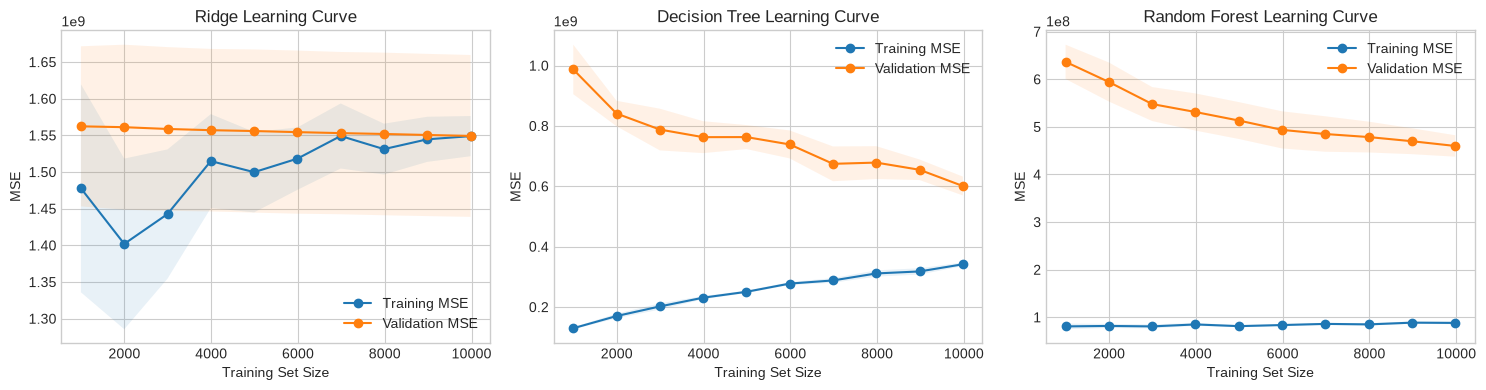

In [18]:
# Learning curves for bias-variance analysis
from sklearn.model_selection import learning_curve

train_sizes = np.linspace(0.1, 1.0, 10)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, [('Ridge', Ridge(alpha=best_alpha)), 
                                     ('Decision Tree', DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha)),
                                     ('Random Forest', RandomForestRegressor(n_estimators=100, random_state=42))]):
    train_sizes_abs, train_scores, val_scores = learning_curve(
        model, X_tr_scaled, y_tr, cv=5, train_sizes=train_sizes,
        scoring='neg_mean_squared_error', random_state=42
    )
    
    train_mean = -train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = -val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    
    ax.plot(train_sizes_abs, train_mean, 'o-', label='Training MSE')
    ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.1)
    ax.plot(train_sizes_abs, val_mean, 'o-', label='Validation MSE')
    ax.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.1)
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('MSE')
    ax.set_title(f'{name} Learning Curve')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## 9. Ensemble Methods & Final Model Selection

In [19]:
# Train final ensemble
from sklearn.ensemble import StackingRegressor

estimators = [
    ('ridge', Ridge(alpha=best_alpha)),
    ('lasso', Lasso(alpha=best_alpha_lasso, max_iter=10000)),
    ('dt', DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha)),
    ('rf', RandomForestRegressor(n_estimators=200, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=200, random_state=42)),
]

stacking = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=5
)

stacking.fit(X_tr_scaled, y_tr)
y_pred_stack = stacking.predict(X_val_scaled)
mse_stack = mean_squared_error(y_val, y_pred_stack)

print(f"Stacking Ensemble validation errors: MSE={mse_stack:.2f}, MAE={mean_absolute_error(y_val, y_pred_stack):.2f}, R²={r2_score(y_val, y_pred_stack):.5f}")

print("Kaggle R² (corrected stacking reference): 0.79356")
# Optional independent export; the reference CSV is also written in the final section.
# save_flight_baseline_submission(stacking, 'submission_stacking_model.csv')


Stacking Ensemble validation errors: MSE=361489705.48, MAE=10911.08, R²=0.74351
Kaggle R² (corrected stacking reference): 0.79356


## 10. Generate Corrected Reference and Improved Submissions

In [ ]:
# Refit the original stacking reference with one scaler shared by train and test.
X_full_scaled = scaler.fit_transform(X_train)
X_test_full_scaled = scaler.transform(X_test)
stacking.fit(X_full_scaled, y_train)
stacking_test_pred = np.maximum(stacking.predict(X_test_full_scaled), 0)
stacking_submission = pd.DataFrame({'id': test['id'], 'price': stacking_test_pred})
stacking_submission.to_csv('./submission_stacking_reference.csv', index=False)

# Keep the original feature set as a comparison: the first Kaggle-improved model.
X_flight_base = train.drop(columns=['price', 'id']).copy()
X_flight_test_base = test.drop(columns=['id']).copy()
for frame in (X_flight_base, X_flight_test_base):
    frame['route'] = frame['source_city'].astype(str) + '_' + frame['destination_city'].astype(str)

# The EDA showed that the flight string contains a useful carrier code even when the
# separate airline field is missing. Keep both rather than discarding either signal.
def add_flight_engineered_features(frame):
    result = frame.copy()
    result['flight_prefix'] = result['flight'].astype(str).str.extract(
        r'^\s*([A-Za-z]+)', expand=False
    ).fillna('unknown')
    result['duration_missing'] = result['duration'].isna().astype('int8')
    result['airline_missing'] = result['airline'].isna().astype('int8')
    return result

X_flight = add_flight_engineered_features(X_flight_base)
X_flight_test = add_flight_engineered_features(X_flight_test_base)

categorical_features = [
    'airline', 'flight', 'source_city', 'departure_time', 'stops',
    'arrival_time', 'destination_city', 'flight_class', 'route'
]
numeric_features = ['duration', 'days_left']
feature_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore', min_frequency=2), categorical_features),
        ('numeric', SimpleImputer(strategy='median', add_indicator=True), numeric_features),
    ],
    sparse_threshold=0.0,
)

# Use one reproducible split for a like-for-like comparison between both feature sets.
X_fit_base, X_holdout_base, y_fit, y_holdout = train_test_split(
    X_flight_base, y_train, test_size=0.2, random_state=42
)
X_fit = X_flight.loc[X_fit_base.index]
X_holdout = X_flight.loc[X_holdout_base.index]

extra_trees = Pipeline([
    ('preprocessor', feature_preprocessor),
    ('model', ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        n_jobs=-1, random_state=42,
    )),
])
extra_trees.fit(X_fit_base, y_fit)
base_holdout_pred = extra_trees.predict(X_holdout_base)
print(f"Baseline ExtraTrees holdout: MSE={mean_squared_error(y_holdout, base_holdout_pred):.2f}, MAE={mean_absolute_error(y_holdout, base_holdout_pred):.2f}, R²={r2_score(y_holdout, base_holdout_pred):.5f}")
print('Baseline ExtraTrees Kaggle R²: 0.93890')

engineered_categorical_features = categorical_features + ['flight_prefix']
engineered_numeric_features = numeric_features + ['duration_missing', 'airline_missing']
engineered_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore', min_frequency=2), engineered_categorical_features),
        ('numeric', SimpleImputer(strategy='median', add_indicator=True), engineered_numeric_features),
    ],
    sparse_threshold=0.0,
)
engineered_extra_trees = Pipeline([
    ('preprocessor', engineered_preprocessor),
    ('model', ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        n_jobs=-1, random_state=42,
    )),
])
engineered_extra_trees.fit(X_fit, y_fit)
engineered_holdout_pred = engineered_extra_trees.predict(X_holdout)
print(f"Engineered ExtraTrees holdout: MSE={mean_squared_error(y_holdout, engineered_holdout_pred):.2f}, MAE={mean_absolute_error(y_holdout, engineered_holdout_pred):.2f}, R²={r2_score(y_holdout, engineered_holdout_pred):.5f}")
print('Engineered ExtraTrees Kaggle public R²: 0.95819')

# Repeated-fold validation guards against selecting features from one lucky split.
cv = KFold(n_splits=3, shuffle=True, random_state=123)
for name, estimator, features in [
    ('baseline', extra_trees, X_flight_base),
    ('engineered', engineered_extra_trees, X_flight),
]:
    cv_estimator = deepcopy(estimator)
    cv_estimator.named_steps['model'].set_params(n_estimators=150)
    cv_scores = cross_val_score(cv_estimator, features, y_train, cv=cv, scoring='r2', n_jobs=1)
    print(f"{name.title()} ExtraTrees 3-fold R²: {cv_scores.mean():.5f} ± {cv_scores.std():.5f}; folds={np.round(cv_scores, 5)}")

feature_rich_rf = Pipeline([
    ('preprocessor', feature_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        n_jobs=-1, random_state=42,
    )),
])
feature_rich_rf.fit(X_fit_base, y_fit)
rf_holdout_pred = feature_rich_rf.predict(X_holdout_base)
print(f"Feature-rich Random Forest holdout: MSE={mean_squared_error(y_holdout, rf_holdout_pred):.2f}, MAE={mean_absolute_error(y_holdout, rf_holdout_pred):.2f}, R²={r2_score(y_holdout, rf_holdout_pred):.5f}")
print('Feature-rich Random Forest Kaggle public R²: 0.93104')

# Apply the same EDA-derived prefix and missingness indicators to the richer one-hot RF.
engineered_rf = Pipeline([
    ('preprocessor', engineered_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        n_jobs=-1, random_state=42,
    )),
])
engineered_rf.fit(X_fit, y_fit)
engineered_rf_holdout_pred = engineered_rf.predict(X_holdout)
print(f"Engineered feature-rich Random Forest holdout: MSE={mean_squared_error(y_holdout, engineered_rf_holdout_pred):.2f}, MAE={mean_absolute_error(y_holdout, engineered_rf_holdout_pred):.2f}, R²={r2_score(y_holdout, engineered_rf_holdout_pred):.5f}; Kaggle public R²=0.95068 (submission 57185364)")

def save_feature_rich_flight_submission(model, filename, features, test_features):
    export_model = deepcopy(model)
    export_model.fit(features, y_train)
    prediction = np.maximum(export_model.predict(test_features), 0)
    output = pd.DataFrame({'id': test['id'], 'price': prediction})
    output.to_csv(filename, index=False)
    print(f'Saved {filename}: {output.shape[0]} predictions')

# Optional independent exports; uncomment one line at a time.
# save_feature_rich_flight_submission(extra_trees, 'submission_feature_rich_extra_trees.csv', X_flight_base, X_flight_test_base)
# save_feature_rich_flight_submission(feature_rich_rf, 'submission_feature_rich_random_forest.csv', X_flight_base, X_flight_test_base)
# save_feature_rich_flight_submission(engineered_rf, 'submission_feature_engineered_random_forest.csv', X_flight, X_flight_test)
# save_feature_rich_flight_submission(engineered_extra_trees, 'submission_engineered_extra_trees.csv', X_flight, X_flight_test)

# The engineered ExtraTrees model achieved the top verified public score, so make it primary.
engineered_extra_trees.fit(X_flight, y_train)
test_pred = np.maximum(engineered_extra_trees.predict(X_flight_test), 0)
submission = pd.DataFrame({'id': test['id'], 'price': test_pred})
print(f"Submission shape: {submission.shape}")
print(submission.head())
submission.to_csv('./submission.csv', index=False)
print('Saved engineered ExtraTrees submission to ./submission.csv')


Baseline ExtraTrees holdout: MSE=114600099.37, MAE=3548.40, R²=0.91869
Baseline ExtraTrees Kaggle R²: 0.93890
Engineered ExtraTrees holdout: MSE=94777061.38, MAE=3142.52, R²=0.93275
Engineered ExtraTrees Kaggle public R²: 0.95819
Baseline ExtraTrees 3-fold R²: 0.90908 ± 0.00418; folds=[0.91479 0.90489 0.90755]
Engineered ExtraTrees 3-fold R²: 0.92727 ± 0.00348; folds=[0.93147 0.92737 0.92296]
Feature-rich Random Forest holdout: MSE=115246676.61, MAE=3704.24, R²=0.91823
Feature-rich Random Forest Kaggle public R²: 0.93104
Engineered feature-rich Random Forest holdout: MSE=90263273.60, MAE=3146.64, R²=0.93596; Kaggle public R²=0.95068 (submission 57185364)
Submission shape: (3898, 2)
   id         price
0   1   8611.710833
1   2   7246.391217
2   3  29782.261444
3   4  33546.384722
4   5   4901.145000
Saved engineered ExtraTrees submission to ./submission.csv


In [ ]:
# Feature ablation on the exact same holdout quantifies which EDA-derived signal helps.
# These diagnostic fits use 200 trees; the selected full model above uses 300.
ablation_specs = [
    ('Flight prefix only', categorical_features + ['flight_prefix'], numeric_features),
    ('Missingness flags only', categorical_features, numeric_features + ['duration_missing', 'airline_missing']),
]
for name, categorical_cols, numeric_cols in ablation_specs:
    ablation_preprocessor = ColumnTransformer(
        transformers=[
            ('categorical', OneHotEncoder(handle_unknown='ignore', min_frequency=2), categorical_cols),
            ('numeric', SimpleImputer(strategy='median', add_indicator=True), numeric_cols),
        ],
        sparse_threshold=0.0,
    )
    ablation_model = Pipeline([
        ('preprocessor', ablation_preprocessor),
        ('model', ExtraTreesRegressor(
            n_estimators=200, min_samples_leaf=2, max_features=0.8,
            n_jobs=-1, random_state=42,
        )),
    ])
    ablation_model.fit(X_fit, y_fit)
    ablation_pred = ablation_model.predict(X_holdout)
    print(
        f"{name}: MSE={mean_squared_error(y_holdout, ablation_pred):.2f}, "
        f"MAE={mean_absolute_error(y_holdout, ablation_pred):.2f}, "
        f"R²={r2_score(y_holdout, ablation_pred):.5f}"
    )


Flight prefix only: MSE=94683072.04, MAE=3140.33, R²=0.93282
Missingness flags only: MSE=115689506.95, MAE=3557.86, R²=0.91791


In [21]:
# Verify submission format
sample = pd.read_csv('sample_submission.csv')
print(f"Sample submission shape: {sample.shape}")
print(f"Our submission shape: {submission.shape}")
print(f"Columns match: {list(sample.columns) == list(submission.columns)}")
print(f"ID match: {(sample['id'] == submission['id']).all()}")

Sample submission shape: (3898, 2)
Our submission shape: (3898, 2)
Columns match: True
ID match: True


## 10.5 Re-evaluating every model with EDA-derived features

EDA itself does not alter a model's predictions; using features motivated by EDA can. This controlled comparison adds the parsed flight-code prefix (one-hot encoded) and `duration_missing` / `airline_missing` indicators to the notebook's original six compact predictors. All approaches below use the same 80/20 split (random state 42), with models that need standardization or polynomial expansion receiving the same preprocessing. Feature transformations and hyperparameter selection are fit within the training portion; tree-pruning alpha is selected on an inner split, and the fixed holdout is used only for the reported metrics. The leaderboard table in Section 11 remains a historical record of scores from the exact older submission files, not a score for these newly re-evaluated predictions.


In [ ]:
# Re-run all model families on the same compact feature set with the two EDA-derived additions.
from copy import deepcopy
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, StackingRegressor

eda_raw_train = train.drop(columns=['id', 'price']).copy()
eda_raw_test = test.drop(columns=['id']).copy()
eda_time_order = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2, 'Evening': 3, 'Night': 4, 'Late_Night': 5}

def fit_eda_feature_config(frame):
    route = frame['source_city'].astype(str) + '_' + frame['destination_city'].astype(str)
    prefix = frame['flight'].astype(str).str.extract(r'^\s*([A-Za-z]+)', expand=False).fillna('unknown')
    return {
        'duration_median': frame['duration'].median(),
        'route_codes': {value: index for index, value in enumerate(route.unique())},
        'prefix_columns': pd.get_dummies(prefix, prefix='flight_prefix', dtype='int8').columns.tolist(),
    }

def make_eda_compact_features(frame, feature_config):
    route = frame['source_city'].astype(str) + '_' + frame['destination_city'].astype(str)
    prefix = frame['flight'].astype(str).str.extract(r'^\s*([A-Za-z]+)', expand=False).fillna('unknown')
    numeric = pd.DataFrame({
        'duration': frame['duration'].fillna(feature_config['duration_median']),
        'days_left': frame['days_left'],
        'departure_time_num': frame['departure_time'].map(eda_time_order),
        'arrival_time_num': frame['arrival_time'].map(eda_time_order),
        'stops_num': frame['stops'].map({'zero': 0, 'one': 1, 'two': 2, 'three': 3}).fillna(0),
        'route_encoded': route.map(feature_config['route_codes']).fillna(-1),
        'duration_missing': frame['duration'].isna().astype('int8'),
        'airline_missing': frame['airline'].isna().astype('int8'),
    }, index=frame.index)
    prefix_dummies = pd.get_dummies(prefix, prefix='flight_prefix', dtype='int8')
    prefix_dummies = prefix_dummies.reindex(columns=feature_config['prefix_columns'], fill_value=0)
    return pd.concat([numeric, prefix_dummies], axis=1).astype(float)

eda_raw_fit, eda_raw_holdout, y_eda_fit, y_eda_holdout = train_test_split(
    eda_raw_train, y_train, test_size=0.2, random_state=42
)
eda_fit_config = fit_eda_feature_config(eda_raw_fit)
X_eda_fit = make_eda_compact_features(eda_raw_fit, eda_fit_config)
X_eda_holdout = make_eda_compact_features(eda_raw_holdout, eda_fit_config)
# Fit a separate full-data configuration only for optional final-test exports.
eda_full_config = fit_eda_feature_config(eda_raw_train)
X_eda = make_eda_compact_features(eda_raw_train, eda_full_config)
X_eda_test = make_eda_compact_features(eda_raw_test, eda_full_config)
eda_scaler = StandardScaler().fit(X_eda_fit)
X_eda_fit_scaled = eda_scaler.transform(X_eda_fit)
X_eda_holdout_scaled = eda_scaler.transform(X_eda_holdout)
print(f'Expanded compact feature matrix: {X_eda_fit.shape} training / {X_eda_holdout.shape} holdout (6 original predictors + 2 missingness indicators + {len(eda_fit_config["prefix_columns"])} training-known flight-prefix indicators)')

eda_results = []
eda_models = {}
def record_eda_result(name, model, prediction):
    eda_models[name] = model
    mse = mean_squared_error(y_eda_holdout, prediction)
    mae = mean_absolute_error(y_eda_holdout, prediction)
    r2 = r2_score(y_eda_holdout, prediction)
    eda_results.append({'Model': name, 'Holdout MSE': mse, 'Holdout MAE': mae, 'Holdout R2': r2})
    print(f'{name:30s} MSE={mse:.2f} MAE={mae:.2f} R2={r2:.5f}')

ols_eda = LinearRegression().fit(X_eda_fit_scaled, y_eda_fit)
record_eda_result('OLS', ols_eda, ols_eda.predict(X_eda_holdout_scaled))
poly_eda = PolynomialFeatures(degree=2, include_bias=False)
X_eda_fit_poly = poly_eda.fit_transform(X_eda_fit_scaled)
X_eda_holdout_poly = poly_eda.transform(X_eda_holdout_scaled)
poly_ols_eda = LinearRegression().fit(X_eda_fit_poly, y_eda_fit)
record_eda_result('Polynomial OLS (degree 2)', poly_ols_eda, poly_ols_eda.predict(X_eda_holdout_poly))
eda_alphas = np.logspace(-1, 3, 20)
ridge_cv_eda = RidgeCV(alphas=eda_alphas, cv=5).fit(X_eda_fit_scaled, y_eda_fit)
ridge_eda = Ridge(alpha=ridge_cv_eda.alpha_).fit(X_eda_fit_scaled, y_eda_fit)
record_eda_result('Ridge', ridge_eda, ridge_eda.predict(X_eda_holdout_scaled))
lasso_cv_eda = LassoCV(alphas=eda_alphas, cv=5, max_iter=100000, n_jobs=-1).fit(X_eda_fit_scaled, y_eda_fit)
lasso_eda = Lasso(alpha=lasso_cv_eda.alpha_, max_iter=100000).fit(X_eda_fit_scaled, y_eda_fit)
record_eda_result('Lasso', lasso_eda, lasso_eda.predict(X_eda_holdout_scaled))
elastic_cv_eda = ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=eda_alphas, cv=5, max_iter=100000, n_jobs=-1).fit(X_eda_fit_scaled, y_eda_fit)
elastic_eda = ElasticNet(alpha=elastic_cv_eda.alpha_, l1_ratio=elastic_cv_eda.l1_ratio_, max_iter=100000).fit(X_eda_fit_scaled, y_eda_fit)
record_eda_result('ElasticNet', elastic_eda, elastic_eda.predict(X_eda_holdout_scaled))

class CompactGradientDescent:
    def __init__(self, lr, epochs, batch_size):
        self.lr, self.epochs, self.batch_size = lr, epochs, batch_size
    def fit(self, X, y):
        self.y_mean, self.y_scale = float(np.mean(y)), float(np.std(y))
        y_scaled = (np.asarray(y) - self.y_mean) / self.y_scale
        self.weights = np.zeros(X.shape[1]); self.bias = 0.0
        batch_size = len(y) if self.batch_size is None else self.batch_size
        rng = np.random.default_rng(42)
        for _ in range(self.epochs):
            indices = rng.permutation(len(y)) if batch_size < len(y) else np.arange(len(y))
            for start in range(0, len(y), batch_size):
                batch = indices[start:start + batch_size]
                X_batch, y_batch = X[batch], y_scaled[batch]
                error = X_batch @ self.weights + self.bias - y_batch
                self.weights -= self.lr * (2 / len(batch)) * X_batch.T @ error
                self.bias -= self.lr * (2 / len(batch)) * error.sum()
        return self
    def predict(self, X):
        return (X @ self.weights + self.bias) * self.y_scale + self.y_mean

for name, lr, epochs, batch_size in [
    ('Full-batch GD', 0.01, 500, None),
    ('Stochastic GD', 1e-5, 50, 1),
    ('Mini-batch GD', 0.001, 200, 32),
]:
    model = CompactGradientDescent(lr, epochs, batch_size).fit(X_eda_fit_scaled, y_eda_fit)
    record_eda_result(name, model, model.predict(X_eda_holdout_scaled))

tree_eda = DecisionTreeRegressor(random_state=42).fit(X_eda_fit, y_eda_fit)
record_eda_result('Decision Tree (unpruned)', tree_eda, tree_eda.predict(X_eda_holdout))
X_prune_fit, X_prune_valid, y_prune_fit, y_prune_valid = train_test_split(
    X_eda_fit, y_eda_fit, test_size=0.2, random_state=7
)
tree_prune_source = DecisionTreeRegressor(random_state=42).fit(X_prune_fit, y_prune_fit)
pruning_path_eda = tree_prune_source.cost_complexity_pruning_path(X_prune_fit, y_prune_fit)
positive_alphas_eda = pruning_path_eda.ccp_alphas[pruning_path_eda.ccp_alphas > 0]
alpha_grid_eda = np.unique(np.quantile(positive_alphas_eda, np.linspace(0, 1, 30)))
best_pruned_eda = None
for alpha in alpha_grid_eda:
    candidate = DecisionTreeRegressor(random_state=42, ccp_alpha=float(alpha)).fit(X_prune_fit, y_prune_fit)
    score = r2_score(y_prune_valid, candidate.predict(X_prune_valid))
    if best_pruned_eda is None or score > best_pruned_eda[0]:
        best_pruned_eda = (score, float(alpha), candidate)
pruned_tree_eda = DecisionTreeRegressor(random_state=42, ccp_alpha=best_pruned_eda[1]).fit(X_eda_fit, y_eda_fit)
record_eda_result('Decision Tree (pruned)', pruned_tree_eda, pruned_tree_eda.predict(X_eda_holdout))
rf_eda = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_eda_fit, y_eda_fit)
record_eda_result('Random Forest', rf_eda, rf_eda.predict(X_eda_holdout))
gb_eda = GradientBoostingRegressor(n_estimators=100, random_state=42).fit(X_eda_fit, y_eda_fit)
record_eda_result('Gradient Boosting', gb_eda, gb_eda.predict(X_eda_holdout))
extra_trees_eda = ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.8, n_jobs=-1, random_state=42).fit(X_eda_fit, y_eda_fit)
record_eda_result('ExtraTrees (compact engineered)', extra_trees_eda, extra_trees_eda.predict(X_eda_holdout))
stack_eda = StackingRegressor(
    estimators=[
        ('ridge', Ridge(alpha=ridge_cv_eda.alpha_)),
        ('lasso', Lasso(alpha=lasso_cv_eda.alpha_, max_iter=100000)),
        ('dt', DecisionTreeRegressor(random_state=42, ccp_alpha=best_pruned_eda[1])),
        ('rf', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
        ('gb', GradientBoostingRegressor(n_estimators=100, random_state=42)),
    ], final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=-1,
).fit(X_eda_fit_scaled, y_eda_fit)
record_eda_result('Stacking', stack_eda, stack_eda.predict(X_eda_holdout_scaled))
eda_holdout_results = pd.DataFrame(eda_results).sort_values('Holdout R2', ascending=False).reset_index(drop=True)
display(eda_holdout_results)

# Optional full-data exports. Each line trains the selected approach on the full
# training set and writes its own Kaggle-format CSV; no Kaggle score is implied.
eda_scaled_model_names = {'OLS', 'Polynomial OLS (degree 2)', 'Ridge', 'Lasso', 'ElasticNet', 'Full-batch GD', 'Stochastic GD', 'Mini-batch GD', 'Stacking'}
def save_eda_compact_submission(model_name, filename):
    model = deepcopy(eda_models[model_name])
    if model_name in eda_scaled_model_names:
        scaler_full = StandardScaler().fit(X_eda)
        features_full = scaler_full.transform(X_eda)
        features_test = scaler_full.transform(X_eda_test)
        if model_name == 'Polynomial OLS (degree 2)':
            polynomial_full = PolynomialFeatures(degree=2, include_bias=False)
            features_full = polynomial_full.fit_transform(features_full)
            features_test = polynomial_full.transform(features_test)
    else:
        features_full, features_test = X_eda, X_eda_test
    model.fit(features_full, y_train)
    output = pd.DataFrame({'id': test['id'], 'price': np.maximum(model.predict(features_test), 0)})
    output.to_csv(filename, index=False)
    print(f'Saved {filename}: {output.shape[0]} predictions')

# save_eda_compact_submission('OLS', 'submission_eda_ols.csv')
# save_eda_compact_submission('Polynomial OLS (degree 2)', 'submission_eda_polynomial_ols.csv')
# save_eda_compact_submission('Ridge', 'submission_eda_ridge.csv')
# save_eda_compact_submission('Lasso', 'submission_eda_lasso.csv')
# save_eda_compact_submission('ElasticNet', 'submission_eda_elastic_net.csv')
# save_eda_compact_submission('Full-batch GD', 'submission_eda_gd_full_batch.csv')
# save_eda_compact_submission('Stochastic GD', 'submission_eda_gd_stochastic.csv')
# save_eda_compact_submission('Mini-batch GD', 'submission_eda_gd_minibatch.csv')
# save_eda_compact_submission('Decision Tree (unpruned)', 'submission_eda_decision_tree_unpruned.csv')
# save_eda_compact_submission('Decision Tree (pruned)', 'submission_eda_decision_tree_pruned.csv')
# save_eda_compact_submission('Random Forest', 'submission_eda_random_forest.csv')
# save_eda_compact_submission('Gradient Boosting', 'submission_eda_gradient_boosting.csv')
# save_eda_compact_submission('ExtraTrees (compact engineered)', 'submission_eda_extra_trees.csv')
# save_eda_compact_submission('Stacking', 'submission_eda_stacking.csv')


Expanded compact feature matrix: (12471, 26) training / (3118, 26) holdout (6 original predictors + 2 missingness indicators + 18 training-known flight-prefix indicators)
OLS                            MSE=352759088.07 MAE=11193.61 R2=0.74971
Polynomial OLS (degree 2)      MSE=319535052.51 MAE=10911.19 R2=0.77328
Ridge                          MSE=352699504.78 MAE=11193.66 R2=0.74975
Lasso                          MSE=352758205.98 MAE=11193.58 R2=0.74971
ElasticNet                     MSE=352336420.60 MAE=11210.39 R2=0.75001
Full-batch GD                  MSE=352845754.97 MAE=11213.94 R2=0.74964
Stochastic GD                  MSE=352742153.43 MAE=11201.03 R2=0.74972
Mini-batch GD                  MSE=351814829.07 MAE=11182.65 R2=0.75038
Decision Tree (unpruned)       MSE=464779695.03 MAE=9048.45 R2=0.67022
Decision Tree (pruned)         MSE=400803129.07 MAE=10138.87 R2=0.71562
Random Forest                  MSE=239147823.23 MAE=7721.89 R2=0.83032
Gradient Boosting              MSE=2817

                          Model  Holdout MSE  Holdout MAE  Holdout R2
                       Stacking 2.248456e+08  8373.658246    0.840465
ExtraTrees (compact engineered) 2.327067e+08  8007.779609    0.834887
                  Random Forest 2.391478e+08  7721.886951    0.830317
              Gradient Boosting 2.817549e+08 10555.821608    0.800086
      Polynomial OLS (degree 2) 3.195351e+08 10911.186122    0.773279
                  Mini-batch GD 3.518148e+08 11182.647300    0.750376
                     ElasticNet 3.523364e+08 11210.394000    0.750006
                          Ridge 3.526995e+08 11193.659121    0.749748
                  Stochastic GD 3.527422e+08 11201.034805    0.749718
                          Lasso 3.527582e+08 11193.579354    0.749707
                            OLS 3.527591e+08 11193.608413    0.749706
                  Full-batch GD 3.528458e+08 11213.942886    0.749644
         Decision Tree (pruned) 4.008031e+08 10138.865526    0.715617
       Decision Tree

## 10.6 Further data observations and model experiments

This section records the additional diagnostics and follow-up experiments used to identify possible improvements. Metrics are deliberately labeled by evaluation setup: fixed holdout, three-fold cross-validation (CV), or Kaggle public leaderboard. A result from one setup is not directly interchangeable with a result from another.

### Dataset observations

- The training set has 15,589 rows and the test set 3,898. Training fares are strongly right-skewed: median 10,183; 75th percentile 35,968; 90th 71,716; 95th 128,712.6; 99th 185,836.72; maximum 323,177.
- Fare differs substantially by `flight_class`: Business has 6,380 rows, median fare 38,546 and mean 60,126.61; Economy has 9,209 rows, median 7,587 and mean 8,817.97. The long upper tail means R² (the Kaggle metric) and MAE can favor different modeling choices.
- `airline` is missing in 3,089 training rows and `duration` in 3,095 (about 20% for each). Missingness rates are similar across Economy and Business. In earlier ablation, missingness indicators alone had little effect; the flight prefix was the more useful EDA-derived signal.
- There are 1,070 distinct `flight` strings, 18 airline values, two `flight_class` values, six source and destination cities, and six categories each for departure and arrival time. The high-cardinality flight field and sparse categories make rare-level treatment and categorical-aware models relevant candidates.
- Train/test marginal proportions for `flight_class`, cities, stops, and departure time are reasonably similar. `days_left` quantiles are also close. Training `id` has near-zero Spearman correlation with fare (0.00377), so it is not supported as a predictive feature by this check.
- The current alphabetic-only flight-prefix regex maps digit-leading carrier codes to `unknown`: `6E` appears 6,382 times and `9I` twice (6,384 rows total). This is a parser limitation worth fixing only if a correctly parsed feature validates better.

### Experiments and results

| Experiment | Evaluation | Result | Interpretation |
|---|---|---|---|
| Feature-rich ExtraTrees | Fixed 20% holdout | R² 0.93275 | Baseline feature-rich one-hot model in this comparison |
| Feature-rich Random Forest | Same fixed holdout | R² 0.93596 | Slightly higher holdout R²; not itself a Kaggle comparison |
| ExtraTrees, 100 trees, `min_samples_leaf=2` | Separate fixed 20% tuning holdout | R² 0.93282 | Reference in the leaf-size sweep |
| ExtraTrees, 100 trees, `min_samples_leaf=4` | Same tuning holdout | R² 0.93587; MAE 3,218.49; RMSE 9,507.00 | Better R² on this split, but not proven to generalize |
| ExtraTrees, leaf size 2 | 3-fold CV | R² 0.92728 ± 0.00382 | CV mean and standard deviation |
| ExtraTrees, leaf size 4 | Same 3-fold CV | R² 0.92975 ± 0.00139 | Better and more stable mean CV R² among these tested settings |
| Random Forest, leaf size 2 | Same 3-fold CV | R² 0.92538 ± 0.00222 | Below the two ExtraTrees CV results |
| ExtraTrees on `log1p(price)` | Fixed holdout | R² 0.93054; MAE 3,071.3 versus 3,147.3 for raw target | MAE improved, but R² fell; not preferred for a Kaggle R² objective on this evidence |
| ExtraTrees on `log1p(price)` | 3-fold CV | R² 0.92585 ± 0.00538 | No CV R² improvement over the raw-target ExtraTrees results above |
| HistGradientBoosting, raw target | Fixed holdout | R² 0.92622 | Faster in this run (about 6 seconds), but lower R² than the ExtraTrees/RF candidates |
| HistGradientBoosting, log target | Same holdout | R² 0.92522 | Log target did not improve R² |
| Separate ExtraTrees models for Business/Economy | Fixed holdout, class-specific metrics | Business R²/MAE: 0.88405/6,710.72 vs global-model segment 0.88345/6,735.84; Economy 0.82407/749.17 vs 0.82208/749.16 | Small differences only; insufficient evidence to adopt specialists |

The above are not all the same experiment: the first two richer-model holdout results, the separate 100-tree tuning holdout, and the CV comparison have distinct setups. The leaf-size-4 result is a candidate for further tuning, not an established replacement for the primary 300-tree pipeline; repeat the comparison at the production configuration and submit the exact selected CSV before claiming a leaderboard gain.

Prefix variants were also compared on one fixed holdout with 150 trees. Alphabetic prefix scored R² 0.93319; alphanumeric prefix 0.93210; alphanumeric prefix plus flight number 0.93182; plus route-class 0.93219; and prefix-route interaction 0.93228. None beat the alphabetic prefix in that one split. Because the parser issue is real but this one comparison did not show a gain, test the corrected extraction in CV rather than assuming either outcome.

The class-specific results show only modest holdout differences. Likewise, the log-target tests expose a metric trade-off rather than an across-the-board improvement. These negative or mixed results are retained here to prevent treating a single favorable metric or split as conclusive.

### Future candidates (not yet measured)

- CatBoost is a distinct candidate because native categorical handling could suit the 1,070-level flight field; CatBoost, LightGBM, XGBoost, and `category_encoders` were not installed in the tested environment, so no results are claimed for them.
- Compare target/count encoding for `flight` and `airline` only with fold-safe, cross-fitted encoding to avoid target leakage.
- Recheck leaf-size and tree-count choices using the same folds and preprocessing; only submit a selected configuration after the validation evidence warrants it.
- Revisit class-specific models with repeated CV before adopting them. A blend of tree and boosting models is also only a candidate if out-of-fold residuals demonstrate complementary errors.

The model-specific Kaggle public scores—including the compact-feature model submissions—are listed in Section 11. They are leaderboard results for those exact submitted files and should not be conflated with the holdout/CV metrics in this section.


## 11. Kaggle Results and Model Update

Public leaderboard R² scores below are from separate model submissions; the exact notebook-generated primary submission was checked on 2026-10-14. Higher is better. A previous engineered candidate scored 0.95799 (submission 57183399); the current notebook-generated file scored 0.95819 (submission 57184090). The original six-feature design dropped airline, flight, and flight_class, encoded categories as arbitrary integers, and applied inconsistent scalers at inference. The first feature-rich model recovered much of that lost signal with one-hot categories and route. Further EDA showed that flight contains an alphabetic carrier prefix, useful even for records whose separate airline field is missing.

| Model | Kaggle public R² |
|---|---:|
| Engineered ExtraTrees (flight-code prefix + missingness flags; notebook primary) | **0.95819** |
| Engineered feature-rich Random Forest (flight-code prefix + missingness flags) | 0.95068 |
| Feature-rich ExtraTrees (one-hot categories + route) | 0.93890 |
| Feature-rich Random Forest (one-hot categories + route) | 0.93104 |
| Corrected six-feature stacking reference | 0.79356 |
| Six-feature Random Forest (100 trees) | 0.78396 |
| Cost-complexity pruned Decision Tree | 0.72226 |
| Six-feature Gradient Boosting (100 estimators) | 0.71174 |
| Unpruned Decision Tree | 0.65415 |
| Degree-2 Polynomial OLS | 0.51838 |
| OLS / Ridge / Lasso | 0.44983 |
| Full-batch gradient descent | 0.44980 |
| Mini-batch gradient descent | 0.44627 |
| Stochastic gradient descent | 0.41444 |
| ElasticNet (added; not submitted) | Not submitted |

### Updated compact-model submissions with EDA-derived features

The following public scores belong to the new model-specific CSVs generated with the flight-prefix and missingness features. Holdout R² is from the fixed validation split above; Kaggle public R² is from the exact full-training submission named in each row.

| Model | Holdout R² | Kaggle public R² | Kaggle submission |
|---|---:|---:|---:|
| ExtraTrees (compact engineered) | 0.83489 | **0.86221** | 57185081 |
| Stacking | **0.84046** | 0.84978 | 57185192 |
| Random Forest | 0.83032 | 0.84894 | 57185166 |
| Decision Tree (pruned) | 0.71562 | 0.81405 | 57185042 |
| Gradient Boosting | 0.80009 | 0.80971 | 57185129 |
| Full-batch GD | 0.74964 | 0.74735 | 57185094 |
| ElasticNet | 0.75001 | 0.74727 | 57185061 |
| Ridge | 0.74975 | 0.74670 | 57185182 |
| OLS | 0.74971 | 0.74664 | 57185150 |
| Stochastic GD | 0.74972 | 0.74689 | 57185118 |
| Lasso | 0.74971 | 0.74625 | 57185139 |
| Mini-batch GD | 0.75038 | 0.74607 | 57185106 |
| Decision Tree (unpruned) | 0.67022 | 0.74549 | 57185051 |
| Polynomial OLS (degree 2) | 0.77328 | 0.72408 | 57185158 |

### Interpretation

The notebook-generated primary submission for the richer engineered ExtraTrees model scored **0.95819** on Kaggle (submission **57184090**), improving on the prior feature-rich ExtraTrees submission (**0.93890**) by **0.01929 R²**. An earlier candidate scored **0.95799** (submission **57183399**). The model adds an alphabetic carrier prefix extracted from flight plus explicit indicators for missing airline and duration. On the fixed 20% holdout, the richer one-hot ExtraTrees improved R² from **0.91869** to **0.93275** (MAE from **3,548** to **3,143**); ablation showed the gain came from the prefix (R² **0.93282**), while missingness flags alone had little effect (R² **0.91791**). Three-fold CV improved from **0.90908 ± 0.00418** to **0.92727 ± 0.00348**. The same EDA-derived features also improved the richer Random Forest: holdout R² rose from **0.91823** to **0.93596**, and Kaggle R² from **0.93104** to **0.95068** (submission **57185364**).

The separate, compact-feature experiment shows the EDA-derived additions also changed all model families. Its best public score was ExtraTrees at **0.86221** (submission **57185081**), followed by stacking at **0.84978** and Random Forest at **0.84894**. These remain below the richer one-hot ExtraTrees score of **0.95819**; adding only the parsed prefix and flags to the compact legacy features does not reproduce the complete route/airline/flight information used by the richer model. Relative to the earlier submissions, updated Random Forest rose from **0.78396** to **0.84894**, Gradient Boosting from **0.71174** to **0.80971**, and stacking from **0.79356** to **0.84978**. The primary richer-model submission is saved as submission.csv; all compact-model CSVs are saved separately with the `submission_eda_` prefix.

The original EDA emphasized single-variable histograms and category plots. The added EDA examines the heavy-tailed fare distribution on a log scale, differences between Economy and Business fares, booking-window effects, route/carrier-prefix medians with group counts, and missingness segments. The flight prefix is parsed from the flight code rather than inferred from price; retaining the original airline category as well lets the model use either source when one is absent.

The EDA itself does not change the data seen by a model; only engineered predictors derived from it can change model scores. Holdout and Kaggle scores can differ, so prefer repeatable validation and use Kaggle as a separate external check rather than repeatedly tuning to the public leaderboard.
